In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
def check_nan(adata, name):
    X = adata.X

    if sp.issparse(X):
        nan_count = np.isnan(X.data).sum()
    else:
        nan_count = np.isnan(X).sum()

    print(f"{name} NaN count:", nan_count)

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.8684389464707589 0.9365363673855996
4.665410747940789 4.8702583
4.665410747940789 4.8702583
max 4.8702583


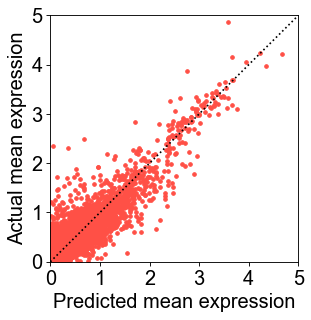

In [3]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_7_and_10/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='#FF5046'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19.pdf"), bbox_inches="tight")


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.7930535679948837 0.9179462448359195
6.2993445 4.8702583
6.2993445 4.8702583
max 6.2993445


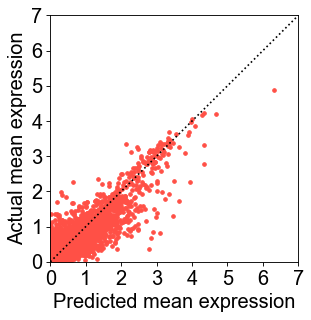

In [4]:

real_data = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
# real_data = real_data_origin[real_data_origin.obs['Group']==1]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_7_and_13/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='#FF5046'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day13_predict_day19.pdf"), bbox_inches="tight")

real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.9495411442986407 0.9823149803429883
5.175658 4.8702583
5.175658 4.8702583
max 5.175658


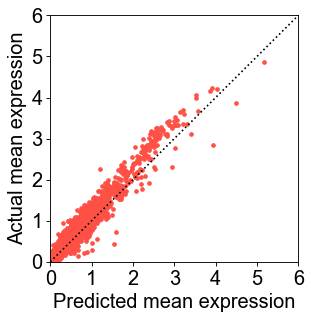

In [5]:

real_data = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
# real_data = real_data_origin[real_data_origin.obs['Group']==1]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_7_and_18/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='#FF5046'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day18_predict_day19.pdf"), bbox_inches="tight")

real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.7458461241753027 0.8890054261553922
5.6881905 4.8702583
5.6881905 4.8702583
max 5.6881905


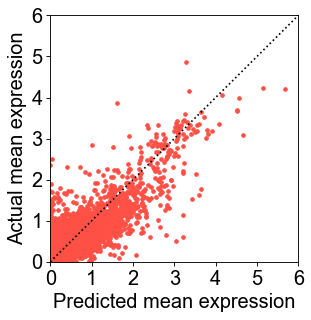

In [6]:

real_data = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
# real_data = real_data_origin[real_data_origin.obs['Group']==1]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_10/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='#FF5046'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_except_day19.pdf"), bbox_inches="tight")

real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.9178404324956257 0.959319211694846
4.6626115 4.8702583
4.6626115 4.8702583
max 4.8702583


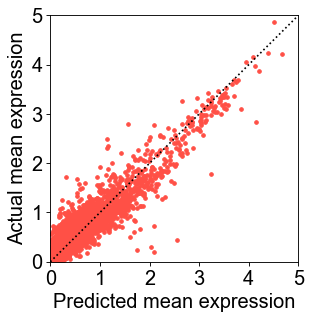

In [7]:

real_data = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
# real_data = real_data_origin[real_data_origin.obs['Group']==1]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_13/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='#FF5046'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day13_predict_day19_big_training_set_except_day19.pdf"), bbox_inches="tight")

real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.9764630111008749 0.9892509729991226
4.7286325 4.8702583
4.7286325 4.8702583
max 4.8702583


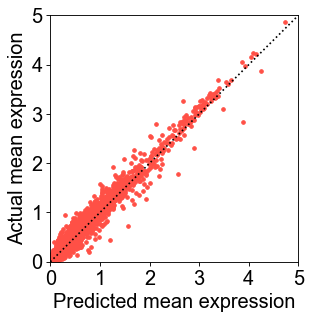

In [8]:

real_data = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
# real_data = real_data_origin[real_data_origin.obs['Group']==1]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_70_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='#FF5046'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day18_predict_day19_big_training_set_except_day19.pdf"), bbox_inches="tight")